In [80]:
import pandas as pd
import numpy as np
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [23]:
raw_df = pd.read_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\cleaned_data\stop_search_train1.csv", index_col=0).drop(["orig_height", "orig_age", "orig_weight","BMI", "vital_flag"], axis=1)
imp_df = pd.read_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\cleaned_data\stop_search_train_imputed.csv")

In [81]:
# Recode race value to make it shorter for plotting
imp_df["SubjectRace"] = np.where(imp_df["SubjectRace"] == "NATIVE HAWAIIAN OR OTHER PACIFIC ISLANDER", "NHPI", imp_df["SubjectRace"])

# Subset of data for PCA
pca_df = imp_df[["District", "StopDescription", "VehicleYear", "VehicleStyle", "VehicleColor", "SubjectRace", "SubjectGender", "SubjectAge", "SubjectHasPhotoID", "SubjectHeight", "SubjectWeight", "SubjectEyeColor", "SubjectHairColor", "Longitude", "Latitude", "Zip", "hour", "night", "month", "year", "weekend", "isDriver", "isLA"]]

cat_cols = ["District", "StopDescription", "VehicleStyle", "VehicleColor", "SubjectRace", "SubjectEyeColor", "SubjectHairColor", "Zip"]


In [82]:
# Recode certain variables as categorical, and make into dummies
pca_df["Zip"] = pca_df["Zip"].astype(str)
pca_df["District"] = pca_df["District"].astype(str)

# Create dummies, drop first to prevent multicollinearity
pca_df_dummies = pd.get_dummies(pca_df, columns=cat_cols, drop_first=True)
pca_df_dummies = pca_df_dummies.astype(float)

# Scale
scaler = StandardScaler()
pca_df_dummies_scaled = scaler.fit_transform(pca_df_dummies)

# PCA
pca = PCA(n_components=2)
pca_results = pca.fit_transform(pca_df_dummies_scaled)

# Make dataframe
fin_pca = pd.DataFrame(data=pca_results, columns=["PC1", "PC2"])

In [97]:
# Adding variables to PCA dataframe to highlight points
fin_pca["Search"] = imp_df["search_occurred"].map({1:"Yes", 0:"No"})
fin_pca["Race"] = imp_df["SubjectRace"]
fin_pca["Gender"] = imp_df["SubjectGender"].map({1:"Female", 0:"Male"})
fin_pca["District"] = imp_df["District"].astype(int)
fin_pca["Zip"] = imp_df["Zip"].astype(int)

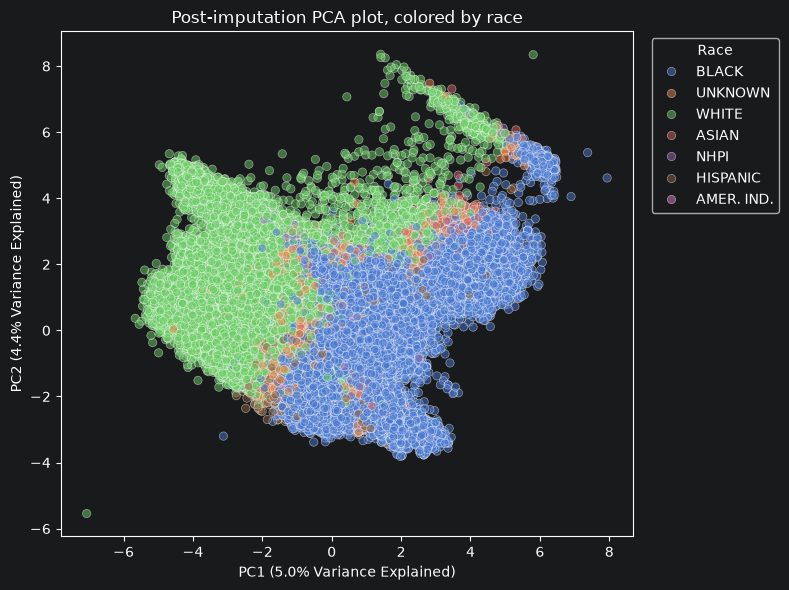

In [88]:
# Plot PC1 and PC2 with race
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x = "PC1", y = "PC2", data = fin_pca, hue = "Race", alpha = 0.5, palette = "muted")
ax.legend(title = "Race", markerscale=1, bbox_to_anchor=(1.02, 1), borderpad=0.4, loc="upper left")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance Explained)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance Explained)")
plt.title("Post-imputation train set PCA plot, colored by race")
plt.tight_layout()
plt.savefig(r"C:\Users\gelet\PycharmProjects\stop-and-search\plots\pca_race.png", bbox_inches="tight")
plt.show()

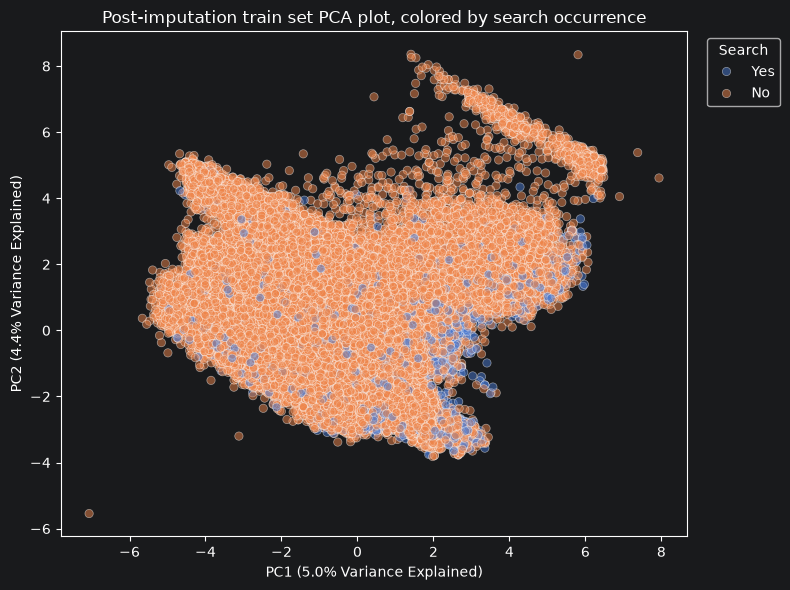

In [90]:
# Plot PC1 and PC2 with search
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x = "PC1", y = "PC2", data = fin_pca, hue = "Search", alpha = 0.5, palette = "muted")
ax.legend(title = "Search", markerscale=1, bbox_to_anchor=(1.02, 1), borderpad=0.4, loc="upper left")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance Explained)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance Explained)")
plt.title("Post-imputation train set PCA plot, colored by search occurrence")
plt.tight_layout()
plt.savefig(r"C:\Users\gelet\PycharmProjects\stop-and-search\plots\pca_search.png", bbox_inches="tight")
plt.show()

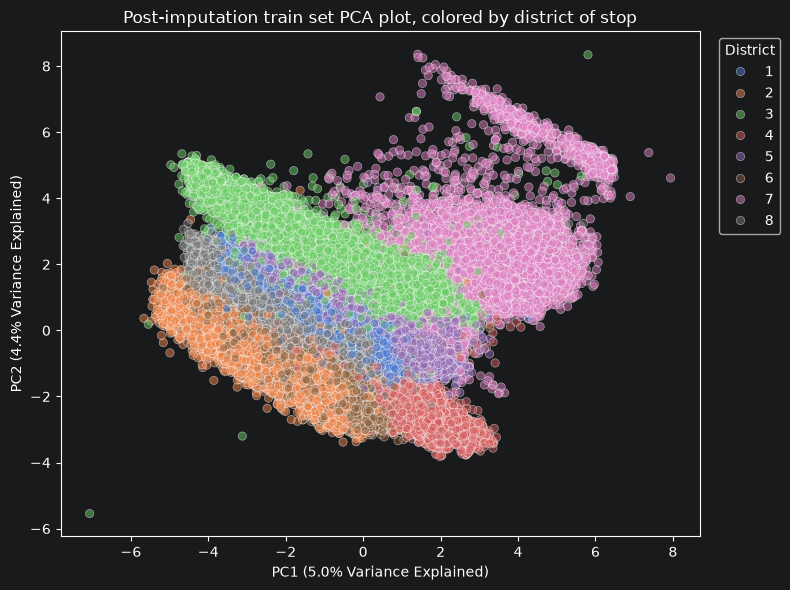

In [100]:
# Plot PC1 and PC2 with district
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x = "PC1", y = "PC2", data = fin_pca, hue = "District", alpha = 0.5, palette = "muted")
ax.legend(title = "District", markerscale=1, bbox_to_anchor=(1.02, 1), borderpad=0.4, loc="upper left")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance Explained)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance Explained)")
plt.title("Post-imputation train set PCA plot, colored by district of stop")
plt.tight_layout()
plt.savefig(r"C:\Users\gelet\PycharmProjects\stop-and-search\plots\pca_district.png", bbox_inches="tight")
plt.show()

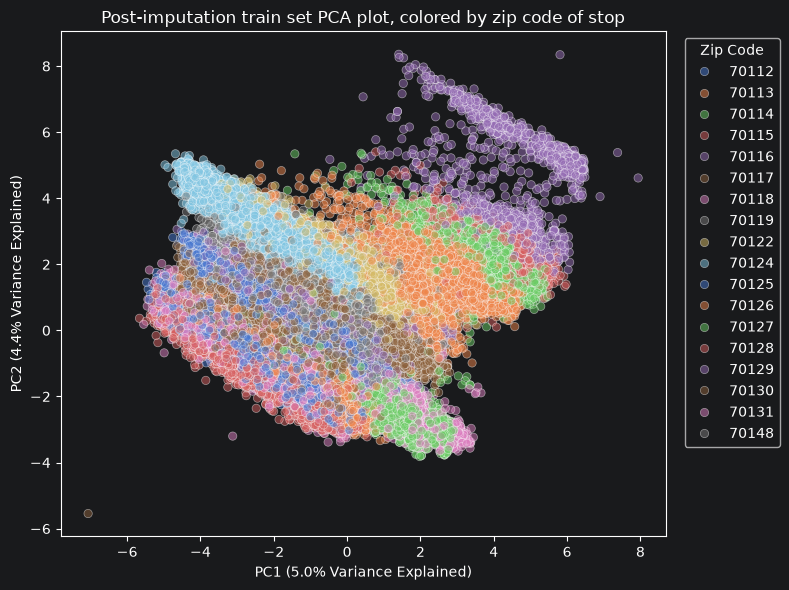

In [99]:
# Plot PC1 and PC2 with zip
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x = "PC1", y = "PC2", data = fin_pca, hue = "Zip", alpha = 0.5, palette = "muted")
ax.legend(title = "Zip Code", markerscale=1, bbox_to_anchor=(1.02, 1), borderpad=0.4, loc="upper left")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance Explained)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance Explained)")
plt.title("Post-imputation train set PCA plot, colored by zip code of stop")
plt.tight_layout()
plt.savefig(r"C:\Users\gelet\PycharmProjects\stop-and-search\plots\pca_zip.png", bbox_inches="tight")
plt.show()

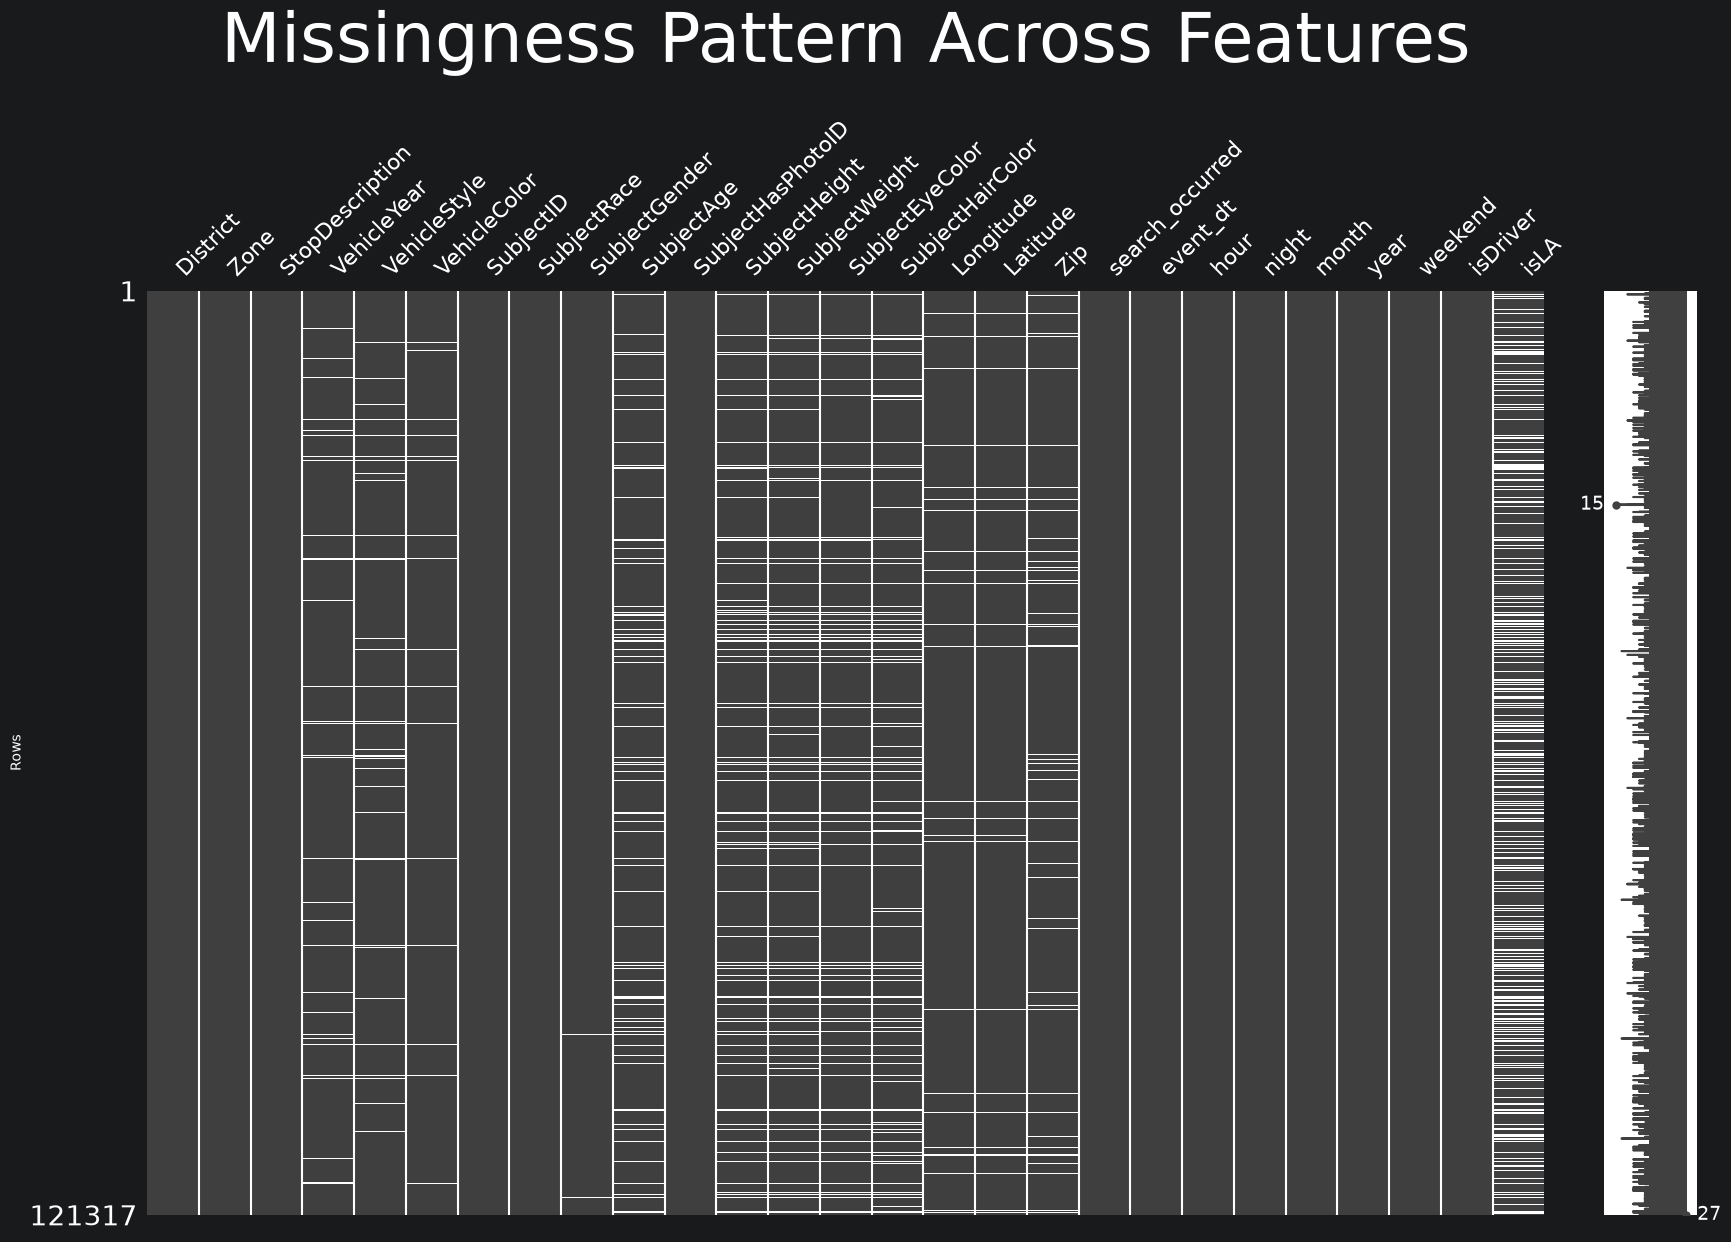

In [12]:
# Visualize missingness matrix in training data
msno.matrix(raw_df, figsize=(20, 12))
plt.title("Missingness Pattern Across Features", fontsize=50, pad=40)
plt.ylabel("Rows")
plt.savefig(r"C:\Users\gelet\PycharmProjects\stop-and-search\plots\missing_matrix.png", bbox_inches="tight")
plt.show()

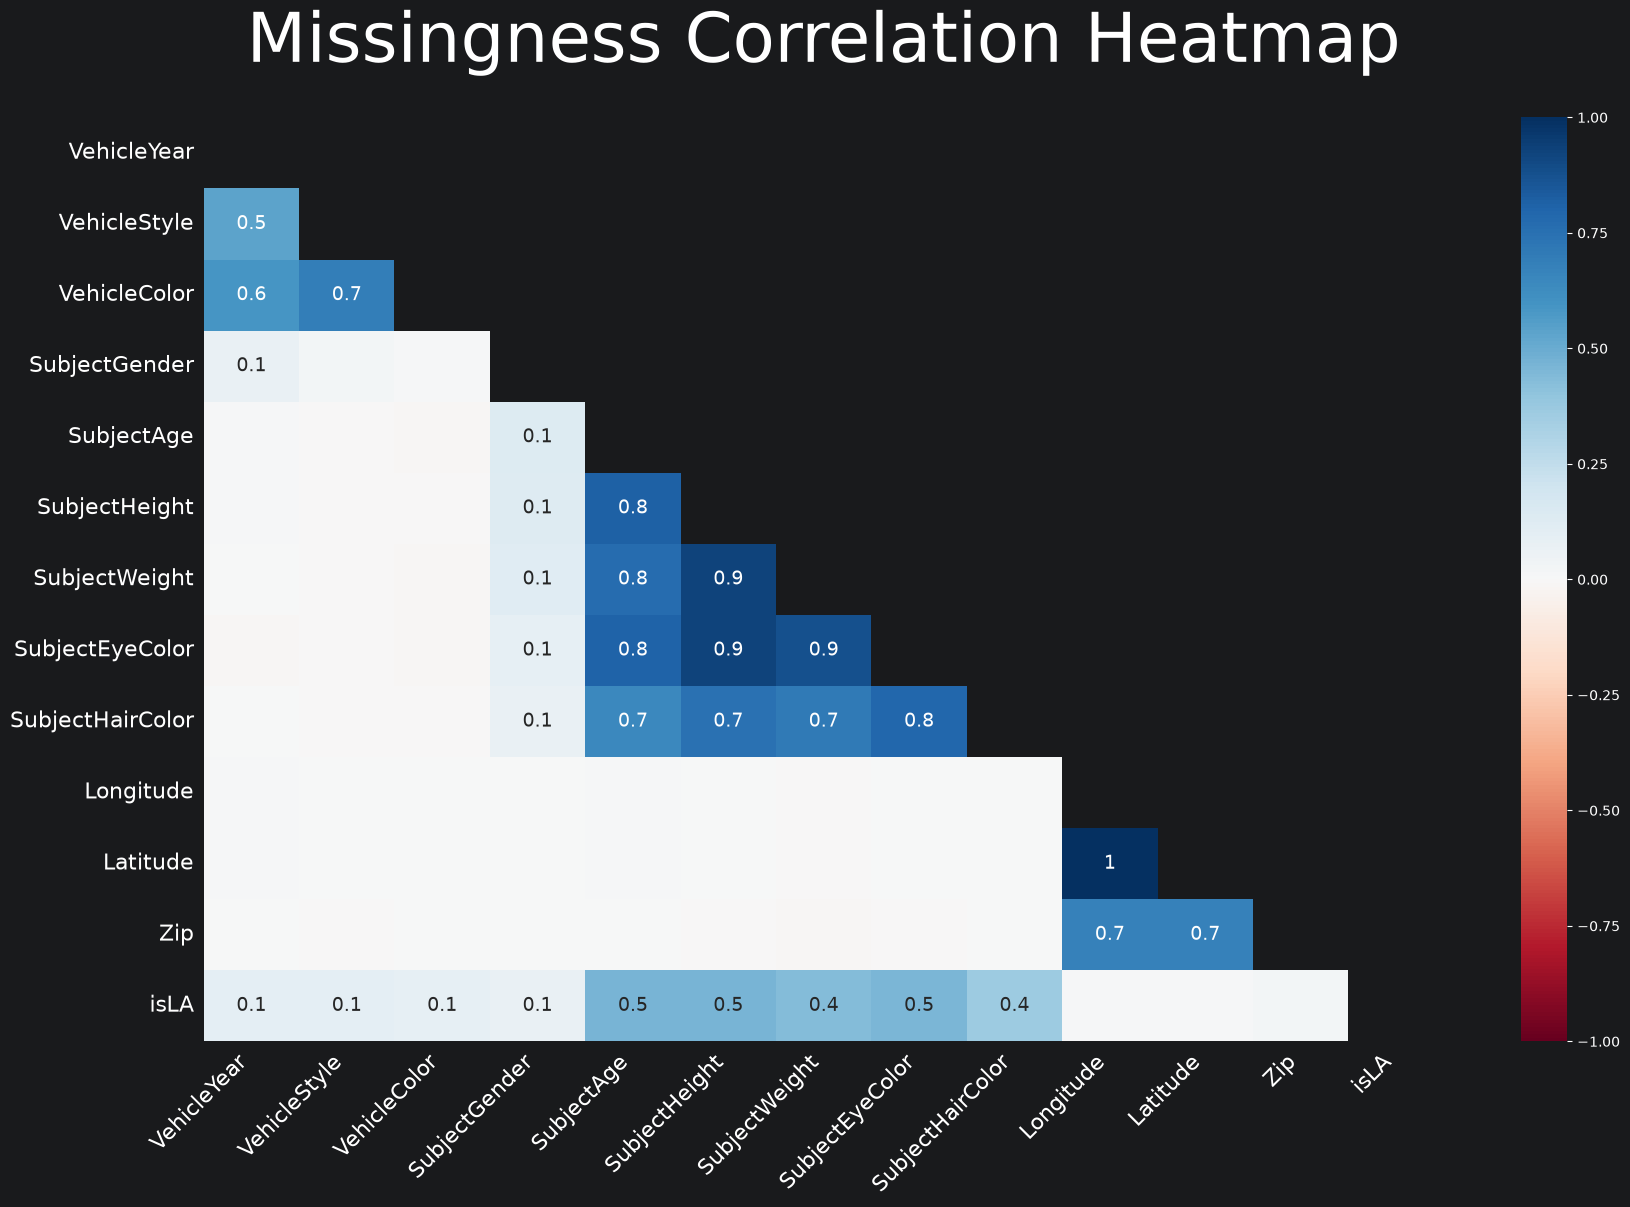

In [24]:
# Visualize missingness correlation in training data; correlation 1 implies missingness in A is associated with missingness in B
msno.heatmap(raw_df, figsize=(20, 12))
plt.title("Missingness Correlation Heatmap", fontsize=50, pad=40)
plt.savefig(r"C:\Users\gelet\PycharmProjects\stop-and-search\plots\missing_corr.png",bbox_inches="tight")
plt.show()